# CA2 – Online Retail: Sales Analysis and Interactive Dashboard

**Module:** Data Visualisation and Communication &nbsp;|&nbsp; **Lecturer:** Taufique Ahmed  
**Student:** Matheus Vinicios de Castilho &nbsp;|&nbsp; **Student number:** 2023336

**GitHub repository:** https://github.com/Matheus-Castilho/CA2-DV 

> **How to run this notebook:** place `Online Retail.xlsx` in the same folder as this notebook (the data is not included in the repository), then select *Kernel → Restart Kernel and Run All Cells*.  
> Libraries used: `pandas`, `matplotlib`, `openpyxl` (to read Excel) and `ipywidgets` (for the dashboard).

<a id="intro"></a>
## 1. Introduction

 #TODO

<a id="setup"></a>
## 2. Setup
mporting the libraries used (pandas for data handling, matplotlib for charts) and setting a consistent chart style

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Show all columns and format decimals neatly
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Same chart style across the whole notebook
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

<a id="load"></a>
## 3. Loading the data

`InvoiceNo` and `StockCode` are read as **text** because some of their values contain letters (for example `C536379` or `85123A`). Without this, pandas would mix numbers and text in the same column.

The original data is kept unchanged in `df_raw`, and all cleaning is done on a copy called `df`. This makes it possible to compare before and after cleaning. Loading the Excel file can take around 30 seconds.

In [2]:
# Read InvoiceNo and StockCode as text because some values contain letters
df_raw = pd.read_excel('Online Retail.xlsx', dtype={'InvoiceNo': str, 'StockCode': str})

# Work on a copy so the original data stays unchanged
df = df_raw.copy()

print(f'Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}')
df.head()

Rows: 541,909  |  Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


<a id="quality"></a>
## 4. Data quality assessment

Before cleaning, the data is checked for problems: wrong data types, missing values, duplicates, invalid records (such as cancellations and negative quantities), items that are not real products, and outliers. **Nothing is removed in this section.** Each issue is only measured here, and the decisions about how to handle it are taken in the cleaning section.

### 4.1 Structure and data types

The table below describes each column and the data type it should have. `df.info()` is then used to compare this with how pandas actually read the data.

| Column | Meaning | Expected type |
|---|---|---|
| `InvoiceNo` | Invoice number. Invoices starting with **C** are cancellations | Text |
| `StockCode` | Product code | Text |
| `Description` | Product name | Text |
| `Quantity` | Units of the product on this invoice line | Whole number |
| `InvoiceDate` | Date and time of the transaction | Date/time |
| `UnitPrice` | Price per unit in pounds sterling (£) | Decimal |
| `CustomerID` | Customer number | ID (text) |
| `Country` | Country where the customer is based | Text |

In [3]:
# Column names, data types and number of non-missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(1), str(3)
memory usage: 45.7+ MB


**Observations:**
- The dataset has **541,909 rows and 8 columns**.
- `InvoiceDate` is already read as a date/time, so sales can be grouped by month, weekday and hour without any conversion.
- `CustomerID` is stored as a decimal number (`float64`). This happens because the column has missing values. It is an identifier, not something to calculate with, so it will be converted to text during cleaning.
- `Description` and `CustomerID` have fewer non-null values than the other columns, so they contain missing data. This is checked in the next section.

### 4.2 Descriptive statistics

Summary statistics (count, mean, median, minimum and maximum) give a quick overview of the numeric columns and highlight values that cannot be correct. Counting the unique values in each column shows how many invoices, products, customers and countries the data covers.

In [4]:
# Summary statistics for the numeric and date columns
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


In [5]:
# Number of different values in each column
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

**Observations:**
- `Quantity` ranges from **−80,995 to +80,995**. Both extremes are the same size, which suggests one very large order that was entered and then cancelled. This is checked in the outliers section.
- `UnitPrice` has a **negative minimum (−£11,062.06)**, which cannot be a real price. Rows like this are accounting adjustments, not sales.
- The **median** quantity is 3 units and the median price is about £2, but both **means** are higher. This shows the data is **right-skewed**: most invoice lines are small, with a few very large ones pulling the average up. For this reason the median is a better measure of a "typical" order line.
- The data covers about **25,900 invoices, 4,070 products, 4,372 customers and 38 countries**, from December 2010 to December 2011.
- `Description` has more unique values than `StockCode` (4,223 vs 4,070), so some products appear under slightly different names. To avoid splitting one product into several rows, product charts will group by `StockCode` and show one name per code.

### 4.3 Missing values

Missing values are counted for every column, and only the columns that have gaps are shown. For each one, the next step is to check whether the affected rows are real sales, because that decides whether they should be kept or removed.

In [6]:
# Count missing values per column and show them as a percentage of all rows
missing = pd.DataFrame({
    'Missing values': df.isna().sum(),
    '% of rows': (df.isna().mean() * 100).round(2)
})
missing[missing['Missing values'] > 0]

,Missing values,% of rows
Description,1454,0.27
CustomerID,135080,24.93


In [7]:
# Are the rows without a description real sales?
no_desc = df[df['Description'].isna()]
print('Unit prices of rows with no description:', no_desc['UnitPrice'].unique())
print('Of these, rows also missing CustomerID:', no_desc['CustomerID'].isna().sum(), 'of', len(no_desc))

Unit prices of rows with no description: [0.]
Of these, rows also missing CustomerID: 1454 of 1454


**Observations:**
- **CustomerID is missing in about 25% of rows** (135,080). These are most likely guest purchases or orders not linked to a customer account. They are still real sales, so removing them would understate revenue by roughly a quarter. They will be **kept and labelled as `Guest`**, and left out only when analysing individual customers.
- **All 1,454 rows without a description have a unit price of £0** and no customer. They cannot be real sales (most likely internal stock adjustments), so they will be removed by the zero-price rule during cleaning.

### 4.4 Duplicates

A row is treated as a duplicate when it is identical to another row in **every** column, including the invoice, product, quantity, price and time.

In [8]:
dup_count = df.duplicated().sum()
print(f'Exact duplicate rows: {dup_count:,} ({dup_count / len(df) * 100:.2f}% of rows)')

# Show a few examples: keep=False marks every copy, not just the second one
df[df.duplicated(keep=False)].sort_values(['InvoiceNo', 'StockCode']).head(6)

Exact duplicate rows: 5,268 (0.97% of rows)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,"17,908.00",United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,"17,908.00",United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,"17,908.00",United Kingdom


**Observations:**
- There are **5,268 exact duplicate rows** (about 1% of the data). The examples show the same product, quantity and price on the same invoice at the same minute, so they are most likely double entries. They will be **removed** so the same sale is not counted twice.
- *Limitation:* a customer could legitimately add the same item twice to one invoice, but the data has no line number to tell these cases apart. Removing them is the safer choice, because it avoids overstating revenue.

### 4.5 Cancellations and invalid records

Invoices that start with the letter **C** are cancellations. Rows with a quantity or unit price of zero or less are also checked, because a real sale must have at least one unit and a positive price.

In [9]:
# Invoices starting with 'C' are cancellations
is_cancelled = df['InvoiceNo'].str.startswith('C')
cancelled_invoices = df.loc[is_cancelled, 'InvoiceNo'].nunique()
all_invoices = df['InvoiceNo'].nunique()

print(f'Cancelled rows: {is_cancelled.sum():,}')
print(f'Cancelled invoices: {cancelled_invoices:,} of {all_invoices:,} '
      f'({cancelled_invoices / all_invoices * 100:.1f}% of all invoices)')
print(f'Rows with Quantity <= 0: {(df["Quantity"] <= 0).sum():,}')
print(f'Rows with UnitPrice <= 0: {(df["UnitPrice"] <= 0).sum():,}')

Cancelled rows: 9,288
Cancelled invoices: 3,836 of 25,900 (14.8% of all invoices)
Rows with Quantity <= 0: 10,624
Rows with UnitPrice <= 0: 2,517


In [10]:
# A few examples of cancelled rows
df[is_cancelled].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,"14,527.00",United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,"15,311.00",United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,"17,548.00",United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,"17,548.00",United Kingdom


**Observations:**
- **About 15% of invoices are cancellations** (3,836 of 25,900). This is important for the business on its own, because cancellations and returns cost money in handling and postage. Cancelled invoices are not completed sales, so they will be **removed** from the revenue analysis.
- Every cancelled row has a negative quantity. The rows with a quantity of zero or less include these cancellations plus other stock corrections.
- Rows with a price of zero or less are free items, damaged stock or accounting adjustments (for example the *"Adjust bad debt"* entries). They cannot represent a real sale, so they will also be **removed**.

### 4.6 Codes that are not products

Product codes normally start with five digits (for example `85123A`). Listing the codes that do not follow this pattern and reading their descriptions shows that several of them are **not merchandise**: postage, fees, discounts and manual adjustments.

In [11]:
# Codes for postage, fees, discounts and manual adjustments (found by checking codes that are not 5 digits)
non_product_codes = ['POST', 'DOT', 'M', 'm', 'C2', 'D', 'S', 'BANK CHARGES', 'AMAZONFEE', 'CRUK', 'B']

non_product = df[df['StockCode'].isin(non_product_codes)]
(non_product
 .groupby('StockCode')
 .agg(Description=('Description', 'first'), Rows=('Description', 'size'))
 .sort_values('Rows', ascending=False))

,Description,Rows
StockCode,,
POST,POSTAGE,1256
DOT,DOTCOM POSTAGE,710
M,Manual,571
C2,CARRIAGE,144
D,Discount,77
S,SAMPLES,63
BANK CHARGES,Bank Charges,37
AMAZONFEE,AMAZON FEE,34
CRUK,CRUK Commission,16


**Observations:**
- There are **2,912 rows** with these codes, covering postage (`POST`, `DOT`, `C2`), fees (`AMAZONFEE`, `BANK CHARGES`, `CRUK`), discounts (`D`), samples (`S`) and manual or bad-debt adjustments (`M`, `m`, `B`).
- If these were kept, *POSTAGE* would appear among the "top products", which would mislead managers. They will be **removed** before the product analysis.
- Other unusual codes, such as gift vouchers (`gift_0001_...`) and a few `DCGS...` items, are **kept** because they are real items sold to customers.

### 4.7 Outliers

Outliers are first checked with the **IQR rule** (interquartile range), a standard method that flags values far outside the middle 50% of the data. Box plots are then used to see how extreme the largest values are, and the most extreme rows are inspected one by one.

In [12]:
# IQR rule: flag values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
for col in ['Quantity', 'UnitPrice']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {outliers:,} rows flagged ({outliers / len(df) * 100:.1f}% of rows)')

Quantity: 58,619 rows flagged (10.8% of rows)
UnitPrice: 39,627 rows flagged (7.3% of rows)


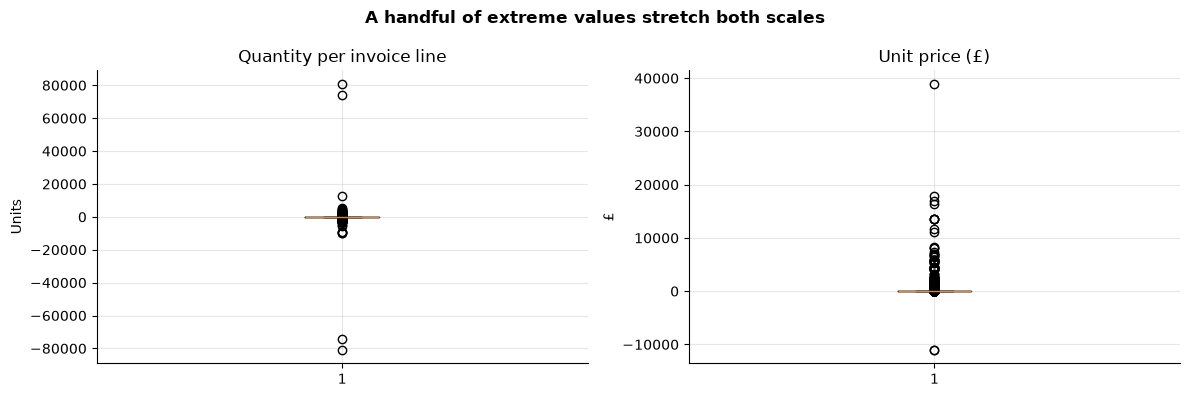

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(df['Quantity'])
axes[0].set_title('Quantity per invoice line')
axes[0].set_ylabel('Units')

axes[1].boxplot(df['UnitPrice'])
axes[1].set_title('Unit price (£)')
axes[1].set_ylabel('£')

fig.suptitle('A handful of extreme values stretch both scales', fontweight='bold')
plt.tight_layout()
plt.show()

In [14]:
# Highest unit prices: are they real products?
df.nlargest(5, 'UnitPrice')[['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice']]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
222681,C556445,M,Manual,-1,"38,970.00"
524602,C580605,AMAZONFEE,AMAZON FEE,-1,"17,836.46"
43702,C540117,AMAZONFEE,AMAZON FEE,-1,"16,888.02"
43703,C540118,AMAZONFEE,AMAZON FEE,-1,"16,453.71"
15016,C537630,AMAZONFEE,AMAZON FEE,-1,"13,541.33"


In [15]:
# The two largest quantities: were these orders cancelled?
largest = df[df['Quantity'].abs().isin([80995, 74215])]
largest[['InvoiceNo', 'InvoiceDate', 'CustomerID', 'Description', 'Quantity', 'UnitPrice']]

,InvoiceNo,InvoiceDate,CustomerID,Description,Quantity,UnitPrice
61619,541431,2011-01-18 10:01:00,"12,346.00",MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
61624,C541433,2011-01-18 10:17:00,"12,346.00",MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04
540421,581483,2011-12-09 09:15:00,"16,446.00","PAPER CRAFT , LITTLE BIRDIE",80995,2.08
540422,C581484,2011-12-09 09:27:00,"16,446.00","PAPER CRAFT , LITTLE BIRDIE",-80995,2.08


In [16]:
# The largest 'Manual' adjustment (£38,970) and the orders around it
df[df['InvoiceNo'].isin(['556444', 'C556445', '556446'])][
    ['InvoiceNo', 'InvoiceDate', 'CustomerID', 'StockCode', 'Description', 'Quantity', 'UnitPrice']]

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice
222680,556444,2011-06-10 15:28:00,"15,098.00",22502,PICNIC BASKET WICKER 60 PIECES,60,649.50
222681,C556445,2011-06-10 15:31:00,"15,098.00",M,Manual,-1,"38,970.00"
222682,556446,2011-06-10 15:33:00,"15,098.00",22502,PICNIC BASKET WICKER 60 PIECES,1,649.50


In [17]:
# Original orders that were reversed shortly after (found above); removed during cleaning
reversed_orders = ['541431', '581483', '556444']

df[df['InvoiceNo'].isin(reversed_orders)][['InvoiceNo', 'Description', 'Quantity', 'UnitPrice']]

,InvoiceNo,Description,Quantity,UnitPrice
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04
222680,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08


**Observations:**
- The IQR rule flags around **11% of quantities** and **7% of prices**. That is far too many to treat as errors. This company is a **wholesaler**, so bulk purchases of dozens or hundreds of units are normal business. These values will be **kept**.
- The box plots show that both scales are stretched by a handful of extreme points, while almost all the data sits close to zero.
- The **highest unit prices** all belong to fees and manual adjustments (`M`, `AMAZONFEE`), not products. They are already handled by the non-product rule from 4.6.
- The **two largest orders** (80,995 and 74,215 units) were each **cancelled within about 15 minutes** by the customer who placed them. Removing the cancellation rows would still leave the original lines in the data.
- In the same way, a customer ordered **60 picnic baskets for £38,970** and received a **manual refund of exactly £38,970 three minutes later**, then placed a new order for just one basket. The original order was clearly a mistake.
- These **three original lines** add about **£285,000 of revenue that never happened**, so they will be **removed** during cleaning. All other large orders are kept.

### 4.8 Time coverage and countries

The date range shows which period the analysis covers and whether every month is complete. The share of rows per country shows whether one market dominates the data, which affects how country charts should be designed.

In [18]:
print('First transaction:', df['InvoiceDate'].min())
print('Last transaction: ', df['InvoiceDate'].max())

# Number of rows per month
df['InvoiceDate'].dt.to_period('M').value_counts().sort_index()

First transaction: 2010-12-01 08:26:00
Last transaction:  2011-12-09 12:50:00


InvoiceDate
2010-12    42481
2011-01    35147
2011-02    27707
2011-03    36748
2011-04    29916
2011-05    37030
2011-06    36874
2011-07    39518
2011-08    35284
2011-09    50226
2011-10    60742
2011-11    84711
2011-12    25525
Freq: M, Name: count, dtype: int64

In [19]:
# Share of rows by country (top 5), as a percentage
(df['Country'].value_counts(normalize=True) * 100).round(1).head(5)

Country
United Kingdom   91.40
Germany           1.80
France            1.60
EIRE              1.50
Spain             0.50
Name: proportion, dtype: float64

In [20]:
# Rows where the country is not known
print('Rows with country "Unspecified":', (df['Country'] == 'Unspecified').sum())

Rows with country "Unspecified": 446


**Observations:**
- The data runs from **1 December 2010 to 9 December 2011**, which is just over one year. Because only one full year is available, it is not possible to compare the same month across two years, so seasonal patterns should be treated with some caution.
- **December 2011 only has 9 days of data.** If it were compared with full months it would look like a sharp fall in sales, so it is kept but **clearly marked** in time-based charts.
- Row counts rise strongly from September to November 2011, which suggests a busy pre-Christmas period. This is explored further in the EDA section.
- The **United Kingdom accounts for about 91% of rows**. In country comparisons the UK would hide every other market, so international markets will also be shown **separately**.
- 446 rows have the country *"Unspecified"*. They are kept because they are still real sales, but they are left out of country comparisons.

### 4.9 Data quality summary

The table below brings together every issue found in this section and how many rows each one affects.

In [21]:
quality_summary = pd.DataFrame({
    'Issue': ['Missing CustomerID', 'Missing Description', 'Exact duplicate rows',
              'Cancelled invoice rows', 'Quantity <= 0', 'UnitPrice <= 0',
              'Non-product codes', 'Mistaken orders later reversed'],
    'Rows affected': [df['CustomerID'].isna().sum(),
                      df['Description'].isna().sum(),
                      df.duplicated().sum(),
                      is_cancelled.sum(),
                      (df['Quantity'] <= 0).sum(),
                      (df['UnitPrice'] <= 0).sum(),
                      df['StockCode'].isin(non_product_codes).sum(),
                      df['InvoiceNo'].isin(reversed_orders).sum()]
})
quality_summary['% of rows'] = (quality_summary['Rows affected'] / len(df) * 100).round(2)
quality_summary

,Issue,Rows affected,% of rows
0,Missing CustomerID,135080,24.93
1,Missing Description,1454,0.27
2,Exact duplicate rows,5268,0.97
3,Cancelled invoice rows,9288,1.71
4,Quantity <= 0,10624,1.96
5,UnitPrice <= 0,2517,0.46
6,Non-product codes,2912,0.54
7,Mistaken orders later reversed,3,0.00


The issues overlap (for example, every cancellation also has a negative quantity), so the counts above should not be added together. The cleaning plan below is applied step by step in Section 5:

| Issue | Decision | Reason (business logic) |
|---|---|---|
| Duplicate rows | Remove | Avoids counting the same sale twice |
| Cancelled invoices | Remove (rate reported in 4.5) | Not completed sales; the analysis focuses on revenue actually earned |
| Quantity or price ≤ 0 | Remove | Cannot be a real sale (adjustments, damaged stock, free items) |
| Missing description | Removed by the price rule | All of these rows have a price of £0 |
| Non-product codes | Remove | Postage and fees would otherwise appear as "products" |
| Three mistaken orders later reversed | Remove the original lines | Keeping them adds ~£285,000 of revenue that never happened |
| Other outliers (IQR) | Keep | Bulk orders are normal for a wholesaler |
| Missing CustomerID | Keep and label `Guest` | About 25% of rows are real sales; excluded only from customer analysis |
| `CustomerID` stored as decimal | Convert to text | It is an identifier, not a number |
| Country "Unspecified" | Keep, leave out of country charts | Real sales, but the market is unknown |
| Partial December 2011 | Keep and mark in charts | Real data, but not comparable with a full month |

**Key takeaways from the data quality assessment**
- Most problems affect only a small share of rows. The exception is the missing CustomerID (25%), which is handled by keeping those sales as `Guest` purchases.
- **About 15% of invoices are cancelled**, which is worth raising with managers as a business issue in its own right.
- Three mistaken orders would inflate revenue by about £285,000 if left in. Checking the extreme values individually, rather than relying only on automatic rules, was necessary to find them.
- The data is dominated by the UK, and December 2011 is incomplete. Both points shape how the charts later in the notebook are designed.

<a id="cleaning"></a>
## 5. Data cleaning and preparation

This section applies the cleaning plan from Section 4.9 in a fixed order. The number of rows left after each step is recorded in a **cleaning log**, so the effect of every decision can be seen and checked. The data is then prepared for analysis by fixing data types, standardising product and country names, and adding new columns such as the revenue of each line.

### 5.1 Applying the cleaning steps

The steps follow the plan in 4.9:

1. **Remove exact duplicate rows**, so no sale is counted twice.
2. **Remove cancelled invoices** (starting with `C`), because they are not completed sales.
3. **Keep only rows with a positive quantity and price**, because anything else cannot be a real sale. This also removes every row with a missing description.
4. **Remove non-product codes** (postage, fees, discounts and adjustments), so they do not appear as products.
5. **Remove the three mistaken orders** that were reversed shortly after being placed (listed in 4.7).

In [22]:
# Record how many rows remain after each step
cleaning_log = [('Original data', len(df))]

# Step 1: remove exact duplicate rows
df = df.drop_duplicates()
cleaning_log.append(('1. Remove duplicate rows', len(df)))

# Step 2: remove cancelled invoices (InvoiceNo starting with 'C')
df = df[~df['InvoiceNo'].str.startswith('C')]
cleaning_log.append(('2. Remove cancelled invoices', len(df)))

# Step 3: keep only rows with a positive quantity and a positive price
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
cleaning_log.append(('3. Remove quantity or price <= 0', len(df)))

# Step 4: remove postage, fees, discounts and manual adjustments
df = df[~df['StockCode'].isin(non_product_codes)]
cleaning_log.append(('4. Remove non-product codes', len(df)))

# Step 5: remove the three mistaken orders that were reversed
df = df[~df['InvoiceNo'].isin(reversed_orders)]
cleaning_log.append(('5. Remove reversed mistaken orders', len(df)))

In [23]:
# Show the cleaning log as a table
log = pd.DataFrame(cleaning_log, columns=['Step', 'Rows remaining'])
log['Rows removed'] = -log['Rows remaining'].diff().fillna(0).astype(int)
log['% of original kept'] = (log['Rows remaining'] / log['Rows remaining'].iloc[0] * 100).round(1)
log

,Step,Rows remaining,Rows removed,% of original kept
0,Original data,541909,0,100.00
1,1. Remove duplicate rows,536641,5268,99.00
2,2. Remove cancelled invoices,527390,9251,97.30
3,3. Remove quantity or price <= 0,524878,2512,96.90
4,4. Remove non-product codes,522571,2307,96.40
5,5. Remove reversed mistaken orders,522568,3,96.40


**Observations:**
- After cleaning, **522,568 rows remain, which is 96.4% of the original data**. The cleaning removes the problems found in Section 4 without throwing away a large share of real sales.
- Cancellations are the biggest single step (9,251 rows), followed by duplicates (5,268 rows).
- Step 3 removes fewer rows than the 10,624 counted in 4.5, because most rows with a negative quantity were cancellations that step 2 had already removed.
- Step 5 removes only 3 rows, but these 3 rows alone were worth about £285,000.

### 5.2 Preparing the data for analysis

With the invalid rows removed, the remaining data is made consistent and easier to analyse:

- **`CustomerID`** is converted from a decimal number to a text ID, and missing values become `Guest`, as planned in 4.3.
- **`Description`** has extra spaces removed, and each product code is given **one name** (its most common description). In 4.2 some codes had several slightly different names, which would otherwise split one product across several bars in a chart. Standardising the names also reveals a couple of extra double entries that used two spellings of the same product, so the duplicate check is run again.
- **`Country`**: `EIRE` is renamed to `Ireland` and `RSA` to `South Africa`, so charts are easier for managers to read.

In [24]:
# CustomerID: whole-number text ID, missing values labelled 'Guest'
df['CustomerID'] = df['CustomerID'].fillna(0).astype(int).astype(str).replace('0', 'Guest')

# Description: remove extra spaces, then give each StockCode its most common name
df['Description'] = df['Description'].str.strip()
product_names = df.groupby('StockCode')['Description'].agg(lambda names: names.mode()[0])
df['Description'] = df['StockCode'].map(product_names)

# Some double entries used two spellings of the same product, so they only become duplicates now
print('Duplicates found after standardising names:', df.duplicated().sum())
df = df.drop_duplicates()

# Country: clearer names for charts
df['Country'] = df['Country'].replace({'EIRE': 'Ireland', 'RSA': 'South Africa'})

Duplicates found after standardising names: 2


**New columns (derived variables)**

| Column | How it is calculated | Why it is needed |
|---|---|---|
| `TotalPrice` | `Quantity × UnitPrice` | Revenue of each line, the main measure for every business question |
| `YearMonth` | Month of `InvoiceDate` (e.g. `2011-03`) | Monthly revenue trend |
| `DayOfWeek` | Name of the day of `InvoiceDate` | Which days are busiest |
| `Hour` | Hour of `InvoiceDate` | Which times of day are busiest |

In [25]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M').astype(str)
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice,YearMonth,DayOfWeek,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,Wednesday,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,Wednesday,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,Wednesday,8


**Order-level table**

Each row in `df` is one product line of an invoice, but many questions are about whole **orders** (for example, "what is a typical order worth?"). The `orders` table below has **one row per invoice**, with its date, customer, country, number of items and total value.

In [26]:
orders = (df.groupby('InvoiceNo')
            .agg(InvoiceDate=('InvoiceDate', 'first'),
                 CustomerID=('CustomerID', 'first'),
                 Country=('Country', 'first'),
                 Items=('Quantity', 'sum'),
                 OrderValue=('TotalPrice', 'sum'))
            .reset_index())

print(f'Orders: {len(orders):,}')
orders.head()

Orders: 19,770


,InvoiceNo,InvoiceDate,CustomerID,Country,Items,OrderValue
0,536365,2010-12-01 08:26:00,17850,United Kingdom,40,139.12
1,536366,2010-12-01 08:28:00,17850,United Kingdom,12,22.20
2,536367,2010-12-01 08:34:00,13047,United Kingdom,83,278.73
3,536368,2010-12-01 08:34:00,13047,United Kingdom,15,70.05
4,536369,2010-12-01 08:35:00,13047,United Kingdom,3,17.85


**Checking the cleaning worked**

The checks below confirm that none of the problems from Section 4 remain. If any check failed, the notebook would stop with an error, so reaching the message "All checks passed" proves the cleaned data is valid.

In [27]:
assert df.duplicated().sum() == 0, 'Duplicates remain'
assert not df['InvoiceNo'].str.startswith('C').any(), 'Cancellations remain'
assert (df['Quantity'] > 0).all() and (df['UnitPrice'] > 0).all(), 'Invalid quantity or price remains'
assert not df['StockCode'].isin(non_product_codes).any(), 'Non-product codes remain'
assert df.isna().sum().sum() == 0, 'Missing values remain'
assert df['StockCode'].groupby(df['StockCode']).size().index.size == df.groupby('StockCode')['Description'].nunique().size
assert (df.groupby('StockCode')['Description'].nunique() == 1).all(), 'A product has more than one name'

print('All checks passed')

All checks passed


In [28]:
# Result of cleaning
guest_share = df.loc[df['CustomerID'] == 'Guest', 'TotalPrice'].sum() / df['TotalPrice'].sum() * 100

print(f'Rows kept: {len(df):,} of {len(df_raw):,} ({len(df) / len(df_raw) * 100:.1f}%)')
print(f'Total revenue after cleaning: £{df["TotalPrice"].sum():,.0f}')
print(f'Share of rows from Guest purchases: {(df["CustomerID"] == "Guest").mean() * 100:.1f}%')
print(f'Share of revenue from Guest purchases: {guest_share:.1f}%')

Rows kept: 522,566 of 541,909 (96.4%)
Total revenue after cleaning: £9,962,730
Share of rows from Guest purchases: 25.1%
Share of revenue from Guest purchases: 15.2%


**Key takeaways from cleaning and preparation**
- The cleaned data keeps **96.4% of the original rows** and gives a total revenue of about **£9.96 million** for the period.
- All checks passed: no duplicates, cancellations, invalid prices or quantities, non-product codes or missing values remain, and every product has a single name.
- **Guest purchases make up about 25% of rows but only about 15% of revenue**, so guest orders tend to be smaller than orders from registered customers. Keeping them was still important, because dropping them would have removed about £1.5 million of real revenue.
- The new `TotalPrice`, `YearMonth`, `DayOfWeek` and `Hour` columns and the `orders` table are the basis for the charts in Section 6 and the dashboard in Section 7.